In [1]:
import pandas as pd 

DADOS = 'tips.csv'

df = pd.read_csv(DADOS)

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


In [5]:
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [6]:
df.describe(exclude='number')

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


In [9]:
for coluna in df.select_dtypes(include='object'):
    print(f"{coluna}: {df[coluna].unique()}")

sex: ['Female' 'Male']
smoker: ['No' 'Yes']
day: ['Sun' 'Sat' 'Thur' 'Fri']
time: ['Dinner' 'Lunch']


<Axes: >

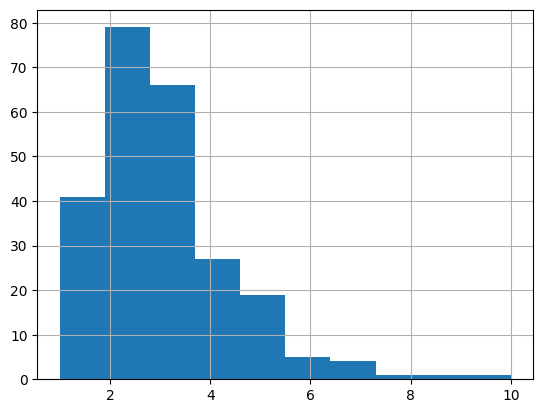

In [11]:
df['tip'].hist()

<Axes: >

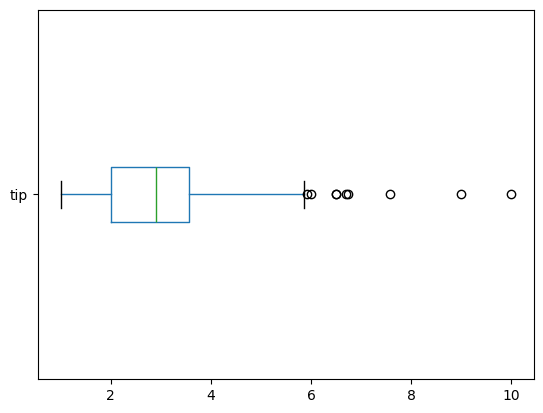

In [12]:
df.boxplot('tip',vert=False,grid=False)

In [13]:
df['tip'].mean()

np.float64(2.99827868852459)

In [14]:
df.where(df['tip'] > df['tip'].mean())

,total_bill,tip,sex,smoker,day,time,size
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,21.01,3.50,Male,No,Sun,Dinner,3.0
3,23.68,3.31,Male,No,Sun,Dinner,2.0
4,24.59,3.61,Female,No,Sun,Dinner,4.0
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3.0
240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
241,NaN,NaN,NaN,NaN,NaN,NaN,NaN
242,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
df.where(df['tip'] > df['tip'].mean(), 0)

,total_bill,tip,sex,smoker,day,time,size
0,0.00,0.00,0,0,0,0,0
1,0.00,0.00,0,0,0,0,0
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,0.00,0.00,0,0,0,0,0
241,0.00,0.00,0,0,0,0,0
242,0.00,0.00,0,0,0,0,0


In [16]:
df.where((df['tip'] > df['tip'].mean()) & (df['day'].isin(['Sat','Sun'])))

,total_bill,tip,sex,smoker,day,time,size
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,21.01,3.50,Male,No,Sun,Dinner,3.0
3,23.68,3.31,Male,No,Sun,Dinner,2.0
4,24.59,3.61,Female,No,Sun,Dinner,4.0
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3.0
240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
241,NaN,NaN,NaN,NaN,NaN,NaN,NaN
242,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:

df_weekend = (
    df.where((df['tip'] > df['tip'].mean()) & (df['day'].isin(['Sat','Sun'])))
    .dropna()
    .reset_index(drop=True)
)
df_weekend

,total_bill,tip,sex,smoker,day,time,size
0,21.01,3.50,Male,No,Sun,Dinner,3.0
1,23.68,3.31,Male,No,Sun,Dinner,2.0
2,24.59,3.61,Female,No,Sun,Dinner,4.0
3,25.29,4.71,Male,No,Sun,Dinner,4.0
4,26.88,3.12,Male,No,Sun,Dinner,4.0
...,...,...,...,...,...,...,...
84,15.69,3.00,Male,Yes,Sat,Dinner,3.0
85,11.61,3.39,Male,No,Sat,Dinner,2.0
86,15.53,3.00,Male,Yes,Sat,Dinner,2.0
87,35.83,4.67,Female,No,Sat,Dinner,3.0


In [20]:
import numpy as np

np.where(df['tip'] > df['tip'].mean())

(array([  2,   3,   4,   5,   7,   9,  11,  13,  14,  15,  17,  18,  19,
         20,  23,  24,  28,  29,  32,  34,  35,  37,  39,  42,  44,  45,
         46,  47,  49,  52,  54,  55,  56,  59,  60,  63,  65,  71,  72,
         73,  76,  77,  78,  80,  81,  83,  85,  87,  88,  89,  90,  91,
         93,  94,  95,  96,  98, 101, 103, 104, 106, 107, 108, 109, 110,
        112, 114, 115, 116, 125, 134, 140, 141, 142, 143, 155, 156, 157,
        160, 164, 165, 167, 170, 171, 172, 173, 174, 175, 178, 179, 180,
        181, 182, 183, 184, 185, 186, 188, 189, 191, 194, 197, 200, 204,
        205, 206, 207, 211, 212, 214, 216, 219, 221, 223, 227, 231, 232,
        234, 238, 239, 243]),)

In [21]:
np.where(df['tip'] > df['tip'].mean(),'Sim','Não')

array(['Não', 'Não', 'Sim', 'Sim', 'Sim', 'Sim', 'Não', 'Sim', 'Não',
       'Sim', 'Não', 'Sim', 'Não', 'Sim', 'Sim', 'Sim', 'Não', 'Sim',
       'Sim', 'Sim', 'Sim', 'Não', 'Não', 'Sim', 'Sim', 'Não', 'Não',
       'Não', 'Sim', 'Sim', 'Não', 'Não', 'Sim', 'Não', 'Sim', 'Sim',
       'Não', 'Sim', 'Não', 'Sim', 'Não', 'Não', 'Sim', 'Não', 'Sim',
       'Sim', 'Sim', 'Sim', 'Não', 'Sim', 'Não', 'Não', 'Sim', 'Não',
       'Sim', 'Sim', 'Sim', 'Não', 'Não', 'Sim', 'Sim', 'Não', 'Não',
       'Sim', 'Não', 'Sim', 'Não', 'Não', 'Não', 'Não', 'Não', 'Sim',
       'Sim', 'Sim', 'Não', 'Não', 'Sim', 'Sim', 'Sim', 'Não', 'Sim',
       'Sim', 'Não', 'Sim', 'Não', 'Sim', 'Não', 'Sim', 'Sim', 'Sim',
       'Sim', 'Sim', 'Não', 'Sim', 'Sim', 'Sim', 'Sim', 'Não', 'Sim',
       'Não', 'Não', 'Sim', 'Não', 'Sim', 'Sim', 'Não', 'Sim', 'Sim',
       'Sim', 'Sim', 'Sim', 'Não', 'Sim', 'Não', 'Sim', 'Sim', 'Sim',
       'Não', 'Não', 'Não', 'Não', 'Não', 'Não', 'Não', 'Não', 'Sim',
       'Não', 'Não',

In [22]:
df['acima_da_media'] = np.where(df['tip'] > df['tip'].mean(),'Sim','Não')

df.head()

,total_bill,tip,sex,smoker,day,time,size,acima_da_media
0,16.99,1.01,Female,No,Sun,Dinner,2,Não
1,10.34,1.66,Male,No,Sun,Dinner,3,Não
2,21.01,3.50,Male,No,Sun,Dinner,3,Sim
3,23.68,3.31,Male,No,Sun,Dinner,2,Sim
4,24.59,3.61,Female,No,Sun,Dinner,4,Sim


In [25]:
df['final_de_semana'] = np.where(df['day'].isin(['Sat','Sun']),'Sim','Não')

display(df.head())
display(df.tail())

,total_bill,tip,sex,smoker,day,time,size,acima_da_media,final_de_semana
0,16.99,1.01,Female,No,Sun,Dinner,2,Não,Sim
1,10.34,1.66,Male,No,Sun,Dinner,3,Não,Sim
2,21.01,3.50,Male,No,Sun,Dinner,3,Sim,Sim
3,23.68,3.31,Male,No,Sun,Dinner,2,Sim,Sim
4,24.59,3.61,Female,No,Sun,Dinner,4,Sim,Sim


,total_bill,tip,sex,smoker,day,time,size,acima_da_media,final_de_semana
239,29.03,5.92,Male,No,Sat,Dinner,3,Sim,Sim
240,27.18,2.00,Female,Yes,Sat,Dinner,2,Não,Sim
241,22.67,2.00,Male,Yes,Sat,Dinner,2,Não,Sim
242,17.82,1.75,Male,No,Sat,Dinner,2,Não,Sim
243,18.78,3.00,Female,No,Thur,Dinner,2,Sim,Não


In [26]:
def outliers(dataframe, coluna, bigode=1.5, nova_coluna='outlier'):
    q1 = dataframe[coluna].quantile(0.25)
    q3 = dataframe[coluna].quantile(0.25)
    iqr = q3 - q1
    limite_inferior = q1 - bigode * iqr
    limite_superior = q3 - bigode * iqr

    condicoes = (dataframe[coluna] < limite_inferior) | (dataframe[coluna] > limite_superior)
    dataframe[nova_coluna] = np.where(condicoes, "Sim","Não")

    return dataframe

In [27]:
outliers(df, 'tip')

,total_bill,tip,sex,smoker,day,time,size,acima_da_media,final_de_semana,outlier
0,16.99,1.01,Female,No,Sun,Dinner,2,Não,Sim,Sim
1,10.34,1.66,Male,No,Sun,Dinner,3,Não,Sim,Sim
2,21.01,3.50,Male,No,Sun,Dinner,3,Sim,Sim,Sim
3,23.68,3.31,Male,No,Sun,Dinner,2,Sim,Sim,Sim
4,24.59,3.61,Female,No,Sun,Dinner,4,Sim,Sim,Sim
...,...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,Sim,Sim,Sim
240,27.18,2.00,Female,Yes,Sat,Dinner,2,Não,Sim,Não
241,22.67,2.00,Male,Yes,Sat,Dinner,2,Não,Sim,Não
242,17.82,1.75,Male,No,Sat,Dinner,2,Não,Sim,Sim


In [28]:
df['outlier'].value_counts()

outlier
Sim    211
Não     33
Name: count, dtype: int64

In [32]:
df[df['outlier'] == 'Sim']

,total_bill,tip,sex,smoker,day,time,size,acima_da_media,final_de_semana,outlier
0,16.99,1.01,Female,No,Sun,Dinner,2,Não,Sim,Sim
1,10.34,1.66,Male,No,Sun,Dinner,3,Não,Sim,Sim
2,21.01,3.50,Male,No,Sun,Dinner,3,Sim,Sim,Sim
3,23.68,3.31,Male,No,Sun,Dinner,2,Sim,Sim,Sim
4,24.59,3.61,Female,No,Sun,Dinner,4,Sim,Sim,Sim
...,...,...,...,...,...,...,...,...,...,...
237,32.83,1.17,Male,Yes,Sat,Dinner,2,Não,Sim,Sim
238,35.83,4.67,Female,No,Sat,Dinner,3,Sim,Sim,Sim
239,29.03,5.92,Male,No,Sat,Dinner,3,Sim,Sim,Sim
242,17.82,1.75,Male,No,Sat,Dinner,2,Não,Sim,Sim
